In [1]:
!pip install torchtext torchdata --index-url https://download.pytorch.org/whl/cu118

Looking in indexes: https://download.pytorch.org/whl/cu118
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 37.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 811.7/811.7 MB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 65.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 104.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 875.6/875.6 kB 54.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 115.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 728.5/728.5 MB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.9/417.9 MB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.4/168.4 MB 14.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 MB 41.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.2/128.2 MB 20.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.1/204

In [2]:
!pip install "numpy<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 104.8 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.21.0+cu124 requires torch==2.6.0, but you have torch 2.2.0+cu118 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
torchtune 0.6.1 requires torchdata==0.11.0, but you have torchdata 0.7.1 which is incompatible.


In [3]:
!pip install portalocker>=2.0.0

In [4]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 95.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [5]:
!python -m spacy download de_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 118.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [96]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


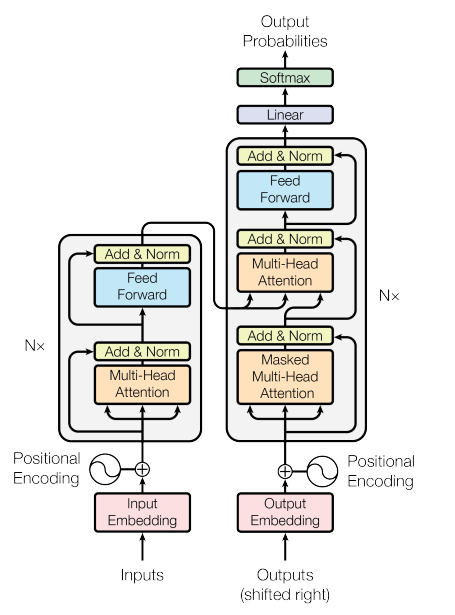

In [103]:
import torch, torchtext

from torchtext.datasets import Multi30k
from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import torch.optim as optim

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import random, math, time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

cuda


### 1. ETL: Loading the dataset

In [104]:
SRC_LANGUAGE = "en"
TARGET_LANGUAGE = "de"

dataset = Multi30k(split=("train"), language_pair=(SRC_LANGUAGE, TARGET_LANGUAGE))

In [105]:
dataset

ShardingFilterIterDataPipe

### 2. EDA: Simple Investigation

In [106]:
sample = next(iter(dataset))
sample

('Two young, White males are outside near many bushes.',
 'Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.')

In [107]:
type(sample)

tuple

In [108]:
sample[0]

'Two young, White males are outside near many bushes.'

In [109]:
sample[1]

'Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.'

In [110]:
# Length
total_length = len(list(iter(dataset)))
total_length

29001

#### 2.1 Split the dataset

In [111]:
train, val, test = dataset.random_split(total_length=total_length, weights={"train": 0.7, "val": 0.2, "test": 0.1}, seed=SEED)

In [112]:
len(list(iter(train))), len(list(iter(val))), len(list(iter(test)))

(20301, 5800, 2900)

### 3. Preprocessing the Dataset

In [113]:
# Constants
SRC_LANGUAGE = "en"
TARGET_LANGUAGE = "de"

#### 3.1. Create Tokenizer

In [114]:
# We need 2 tokenizers to handle 2 different languages
src_tokenizer = get_tokenizer(tokenizer="spacy", language="en_core_web_sm")
target_tokenizer = get_tokenizer(tokenizer="spacy", language="de_core_news_sm")

# Create a dict that holds both tokenizers
tokenization_transform = {}
tokenization_transform[SRC_LANGUAGE] = src_tokenizer
tokenization_transform[TARGET_LANGUAGE] = target_tokenizer

tokenization_transform

{'en': functools.partial(<function _spacy_tokenize at 0x7c184485fec0>, spacy=<spacy.lang.en.English object at 0x7c17c1f90e10>),
 'de': functools.partial(<function _spacy_tokenize at 0x7c184485fec0>, spacy=<spacy.lang.de.German object at 0x7c17a8243e10>)}

In [115]:
# Test
print(sample[0])
print(tokenization_transform[SRC_LANGUAGE](sample[0]))

Two young, White males are outside near many bushes.
['Two', 'young', ',', 'White', 'males', 'are', 'outside', 'near', 'many', 'bushes', '.']


In [116]:
# Test
print(sample[1])
print(tokenization_transform[TARGET_LANGUAGE](sample[1]))

Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.
['Zwei', 'junge', 'weiße', 'Männer', 'sind', 'im', 'Freien', 'in', 'der', 'Nähe', 'vieler', 'Büsche', '.']


In [117]:
#  Helper function to yield list of tokens. Here data is a [(tuple(src, target)]
def yield_tokens(data, lang):
    lang_idxs = {SRC_LANGUAGE: 0, TARGET_LANGUAGE: 1}

    for sample in data:
        yield tokenization_transform[lang](sample[lang_idxs[lang]])  # Here lang = "en" or "de" where as SRC_LANGUAGE = "en", TARGET_LANGAUGE="de"

#### 3.2. Numericalization: Text to Integers

In [118]:
# Generate Vocab and word2idx and id2word for source and target data

# Define special symbols and indices
specials = ["<unk>", "<pad>", "<sos>", "<eos>"]
UNK_IDX, PAD_IDX, SOS_IDX, EOS_IDX = 0, 1, 2, 3   # Make sure the tokens are in order of their indices to properly insert them in vocab

# Generate a dict that holds both source and target vocab
vocab_transform = {}
for lang in [SRC_LANGUAGE, TARGET_LANGUAGE]:
    vocab_transform[lang] = build_vocab_from_iterator(yield_tokens(train, lang), min_freq=2, specials=specials, special_first=True)

# Set UNK_IDX as the default idx. This idx is returned when the token is not found. If not set, it throws RuntimeError when the queried token is not found in the Vocabulary.
for lang in [SRC_LANGUAGE, TARGET_LANGUAGE]:
    vocab_transform[lang].set_default_index(UNK_IDX)

In [119]:
type(vocab_transform[SRC_LANGUAGE])

torchtext.vocab.vocab.Vocab

In [120]:
# Unique vocab - (word2idx)
src_vocab_size = len(vocab_transform[SRC_LANGUAGE])
target_vocab_size = len(vocab_transform[TARGET_LANGUAGE])

src_vocab_size, target_vocab_size

(5207, 6464)

In [121]:
vocab_transform[SRC_LANGUAGE]["<unk>"]

0

In [122]:
vocab_transform[SRC_LANGUAGE]["<huyauhsink>"]

0

In [123]:
vocab_transform[SRC_LANGUAGE](["here", "is", "a", "unknownword", "word"])

[2587, 10, 4, 0, 3217]

In [124]:
vocab_transform[TARGET_LANGUAGE]["<unk>"]

0

In [125]:
# Reverse mapping (idx2word)
src_mapping = vocab_transform[SRC_LANGUAGE].get_itos()
target_mapping = vocab_transform[TARGET_LANGUAGE].get_itos()

In [126]:
src_mapping[0], src_mapping[1], src_mapping[2], src_mapping[3]

('<unk>', '<pad>', '<sos>', '<eos>')

In [127]:
src_mapping[5206]

'zooms'

In [128]:
target_mapping[0], target_mapping[1], target_mapping[2], target_mapping[3]

('<unk>', '<pad>', '<sos>', '<eos>')

In [129]:
target_mapping[6463]

'üppig'

### 4. Prepare the DataLoader

In [130]:
# Create Sequence transforms using decorator functionality - pipeline
def sequence_transform(*transforms):
    def func(text_input):
        for transform in transforms:
            text_input = transform(text_input)
        return text_input
    return func

def tensor_transform(tokens_ids):
    """ADD <sos> and <eos> to the input sequnce idxs and return tensor"""
    return torch.cat((torch.tensor([SOS_IDX]), torch.tensor(tokens_ids), torch.tensor([EOS_IDX])))


# src and target language text transforms to convert raw strings into tensors indices
transforms_pipe = {}
for lang in [SRC_LANGUAGE, TARGET_LANGUAGE]:
    transforms_pipe[lang] = sequence_transform(tokenization_transform[lang], # Tokenization
                                               vocab_transform[lang], # Numericalization
                                               tensor_transform) # Add BOS/EOS and create tensor

Note: *param in the function means, it can accept any number of positional arguments, and they will all be packed into a tuple called transforms.

In [131]:
# Collate Function
def collate_fn(batch):
    src_seqs, target_seqs, src_lengths = [], [], []
    for src_sample, target_sample in batch:
        processed_src = transforms_pipe[SRC_LANGUAGE](src_sample.rstrip("\n"))
        src_seqs.append(processed_src)
        src_lengths.append(processed_src.size(0))
        processed_target = transforms_pipe[TARGET_LANGUAGE](target_sample.rstrip("\n"))
        target_seqs.append(processed_target)
    src_batch = pad_sequence(src_seqs, padding_value=PAD_IDX, batch_first=True)   # Note: batch_first is set to True
    target_batch = pad_sequence(target_seqs, padding_value=PAD_IDX, batch_first=True)
    return src_batch, torch.tensor(src_lengths, dtype=torch.int64), target_batch

In [132]:
# Create DataLoaders
BATCH_SIZE = 64

train_dataloader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_dataloader = DataLoader(val, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_dataloader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

In [133]:
# Test the dataloader
for src_en, src_len, target_de in train_dataloader:
    break

In [134]:
print("English shape: ", src_en.shape)  # (seq_len, batch_size)
print("German shape: ", target_de.shape)   # (seq_len, batch_size)
print(f"Source Length: {src_len.shape}")  # (batch_size,)

English shape:  torch.Size([64, 24])
German shape:  torch.Size([64, 25])
Source Length: torch.Size([64])


### 5. Design the Transformer Model

#### 5.1. Encoder Layer

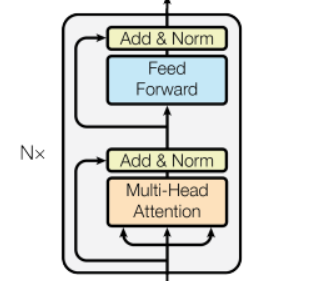

In [135]:
class EncoderLayer(nn.Module):
    def __init__(self, hidden_dim, n_heads, pff_dim, dropout, device):
        super().__init__()
        self.self_attn_layer_norm = nn.LayerNorm(hidden_dim)
        self.pffd_layer_norm = nn.LayerNorm(hidden_dim)
        self.self_attention = MultiHeadAttention(hidden_dim, n_heads, dropout, device)
        self.feedforward = PositionWiseFeedForward(hidden_dim, pff_dim, dropout)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, src, src_mask):
        # src: (bs, src_seq_len, hidden_dim) # already src is embedded + pos encoded
        # src_mask: (bs, 1, 1, src_seq_len)  # if the token is padding, it will be 0, otherwise for non-padding token, 1

        _src, _attn = self.self_attention(src, src, src, src_mask)              # (bs, src_seq_len, hidden_dim) (bs, n_heads, query_len, key_len)
        src = self.self_attn_layer_norm(src + self.dropout(_src))               # (bs, src_seq_len, hidden_dim)

        _src = self.feedforward(src)                                            # (bs, src_seq_len, hidden_dim)
        src = self.pffd_layer_norm(src + self.dropout(_src))                    # (bs, src_seq_len, hidden_dim)
        return src


#### 5.2 MultiHead Attention

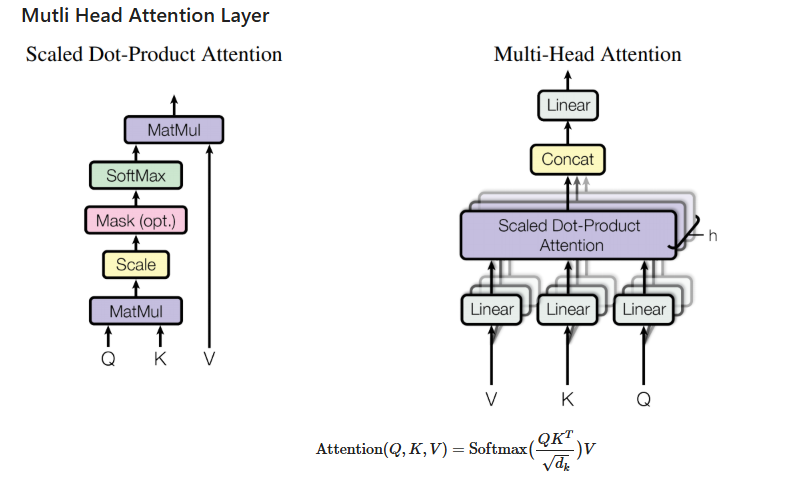

In [136]:
class MultiHeadAttention(nn.Module):
    def __init__(self, hidden_dim, n_heads, dropout, device):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.n_heads = n_heads
        assert hidden_dim % n_heads == 0, f"Unable to create head dimension as hidden_dim:{hidden_dim} is not divisible by heads:{n_heads}"
        self.head_dim = hidden_dim // n_heads

        self.fc_q = nn.Linear(in_features=hidden_dim, out_features=hidden_dim)
        self.fc_k = nn.Linear(in_features=hidden_dim, out_features=hidden_dim)
        self.fc_v = nn.Linear(in_features=hidden_dim, out_features=hidden_dim)

        self.fc_out =  nn.Linear(in_features=hidden_dim, out_features=hidden_dim)

        self.dropout = nn.Dropout(p=dropout)
        self.device = device
        self.scale = torch.sqrt(torch.FloatTensor([self.head_dim])).to(device)   # head_dim

    def forward(self, query, key, value, mask=None):
        """
        For Encoder, q,k,v are same, nothing but our source sentence passed thrice. We perform self attention in encoder.
        For decoder, k and v from encoder and query is from decoder. We perform cross attention here.
        Decoder is basically asking encoder for a query word, on which words in source, it should put focus on
        """
        # src=Q=K=V: (bs, src_seq_len, hidden_dim) = (bs, Q_seq_len, hidden_dim) = (bs, K_seq_len, hidden_dim) = (bs, V_seq_len, hidden_dim) => src_seq_len = Q_seq_len = K_seq_len = V_seq_len
        # mask = (bs, 1, 1, src_seq_len)

        bs = query.shape[0]
        src_seq_len = query.shape[1]
        Q = self.fc_q(query)   # (bs, Q_seq_len, hidden_dim)
        K = self.fc_k(key)   # (bs, K_seq_len, hidden_dim)
        V = self.fc_v(value)   # (bs, V_seq_len, hidden_dim)

        # multihead projection. hidden_dim / n_heads = head_dim
        Q = Q.view(bs, -1, self.n_heads, self.head_dim)  # (bs, src_seq_len, n_heads, head_dim) => (bs, Q_seq_len, n_heads, head_dim)
        K = K.view(bs, -1, self.n_heads, self.head_dim)  # (bs, K_seq_len, n_heads, head_dim)
        V = V.view(bs, -1, self.n_heads, self.head_dim)  # (bs, V_seq_len, n_heads, head_dim)
        Q = Q.permute(0, 2, 1, 3)  # (bs, n_heads, Q_seq_len, head_dim)
        K = K.permute(0, 2, 1, 3)  # (bs, n_heads, K_seq_len, head_dim)
        V = V.permute(0, 2, 1, 3)  # (bs, n_heads, V_seq_len, head_dim)

        energy = torch.matmul(Q, K.permute(0, 1, 3, 2)) / self.scale   #attnscores (bs, n_heads, Q_seq_len, head_dim) (bs, n_heads, head_dim, K_seq_len) => (bs, n_heads, Q_seq_len, K_seq_len)

        # For making attention of padding tokens to 0
        if mask is not None:
            energy = energy.masked_fill(mask==0, -1e10) # mask has non padding as 1 and padding as 0. This fills the true value of condition mask==0 with small value
            # (bs, n_heads, Q_seq_len, K_seq_len) (bs, 1, 1, src_seq_len) => (bs, n_heads, Q_seq_len, K_seq_len)

        attn = torch.softmax(energy, dim=-1)     # Normalizes and gives attn distribution (bs, n_heads, Q_seq_len, K_seq_len)
        x = torch.matmul(self.dropout(attn), V)  # Context vector (bs, n_heads, Q_seq_len, K_seq_len) (bs, n_heads, V_seq_len, head_dim) => (bs, n_heads, Q_seq_len, head_dim)

        # concatention of all the heads - final multi-head attention output (before projecting).
        x = x.permute(0, 2, 1, 3).contiguous()  # perform view effortlessly without device issues  # (bs, Q_seq_len, n_heads, head_dim)
        x = x.view(bs, -1, self.hidden_dim) # (bs, src_seq_len, hidden_dim) => (bs, Q_seq_len, n_heads*head_dim) =>

        # Final linear layer after MHA - linear projection that mixes information across heads.
        x = self.fc_out(x)  # (bs, src_seq_len, hidden_dim)
        return x, attn


**Note:** Think of heads as chopping the sentence(hidden_dim) into different portions(head_dimensions) (hidden_dim = n_heads * head_dim => hidden_dim / head_dim = nheads => hidden_dim /nheads = hidden_dim). Each head may model different relationships within the sequence. One head might model POS, one might model NER, one might model semantic relationship and so on.


```python
attn = torch.softmax(energy, dim=-1)     # Normalizes (bs, n_heads, Q_seq_len, K_seq_len)
x = torch.matmul(self.dropout(attn), V)  # => (bs, n_heads, Q_seq_len, head_dim)
```

---

##### 5.2.1 What is "Attention"?

In this context:

* **"Attention" usually refers to `attn`** — the result of softmax over `energy` (the dot-product scores or compatibility scores between queries and keys).
* This is **before** applying it to the value matrix `V`.

`attn` **(after softmax)** is what we call **the attention weights** or **the "attention"**.

---

## What happens in each step?

1. **`energy`** = score between each query and key
   Shape: `(bs, n_heads, Q_len, K_len)`

2. **`attn = softmax(energy, dim=-1)`**

   * Converts scores into a probability distribution over the keys for each query.
   * This is **what we call the "attention" weights.**

3. **`torch.matmul(attn, V)`**

   * Applies attention weights to the values.
   * This produces the **context vector** (or output of the attention layer), shape: `(bs, n_heads, Q_len, head_dim)`

---


| Variable | Meaning                           | Referred to as “attention”?       |
| -------- | --------------------------------- | --------------------------------- |
| `energy` | Raw alignment scores (Q·Kᵀ / √dₖ) | ❌ No                              |
| `attn`   | Softmax-normalized scores         | ✅ Yes — this **is attention**     |
| `x`      | Weighted sum of `V` using `attn`  | ❌ No — this is the output/context |

In [137]:
import torch
a = torch.randn(1, 2, 3, 4)
b = torch.randn(1, 2, 4, 3)
c = torch.matmul(a, b)
c.shape

torch.Size([1, 2, 3, 3])

#### 5.3 Position-wise Feed forward Layer

In [138]:
class PositionWiseFeedForward(nn.Module):
    def __init__(self, hidden_dim, pff_dim, dropout):
        super().__init__()
        self.fc1 = nn.Linear(in_features=hidden_dim, out_features=pff_dim)  # projection into pff_dim
        self.fc2 = nn.Linear(in_features=pff_dim, out_features=hidden_dim)  # porjecting back to hidden dim
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (bs, src_seq_len, hidden_dim)
        x = self.dropout(torch.relu(self.fc1(x)))  # (bs, src_seq_len, pff_dim)  # relu for non linearity
        x = self.fc2(x)                            # (bs, src_seq_len, hidden_dim)
        return x

Each Feed foward ll try to model the relationships between the words.

#### 5.4 Encoder

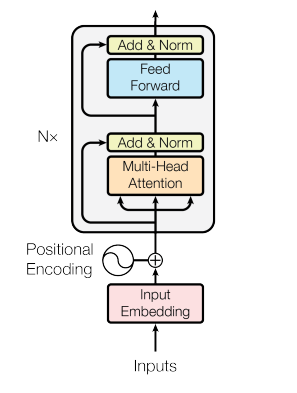

In [139]:
class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, n_layers, n_heads, pff_dim, dropout, device, max_length=100):
        super().__init__()
        self.token_embedding = nn.Embedding(input_dim, embedding_dim=hidden_dim)
        self.positional_encoding = nn.Embedding(max_length, embedding_dim=hidden_dim) # Needed To model position relations which is required for se2seq models # original ppr used sinusoidal encodings.
        self.layers = nn.ModuleList([EncoderLayer(hidden_dim, n_heads, pff_dim, dropout, device) for _ in range(n_layers)])  # we can have Nx of encoder layers
        self.scale = torch.sqrt(torch.FloatTensor([hidden_dim])).to(device)   # Note: Differnt scale from MHA. This is to scale down the token embeddings
        self.dropout = nn.Dropout(dropout)
        self.device = device

    def forward(self, src, src_mask):
        # src: (bs, src_seq_len), src_mask: (bs, 1, 1, src_seq_len)
        bs = src.shape[0]
        src_seq_len = src.shape[1]
        pos_embeds = torch.arange(0, src_seq_len).unsqueeze(dim=0).repeat(bs, 1).to(self.device)  # (src_seq_len,) -> (1, src_seq_len) -> (bs, src_seq_len) # our data has atmost 30 words per sentence. so for safe side we kept max length as 100.

        src = self.dropout((self.token_embedding(src) * self.scale) + self.positional_encoding(pos_embeds))    # (bs, src_seq_len) -> (bs, src_seq_len, hidden_dim) + (bs, src_seq_len) -> (bs, src_seq_len, hidden_dim) => (bs, src_seq_len, hidden_dim)
        for layer in self.layers:
            src = layer(src, src_mask)   # (bs, src_seq_len, hidden_dim)

        return src # last layer encoder context


#### 5.5. Decoder Layer

In [140]:
class DecoderLayer(nn.Module):
    def __init__(self, hidden_dim, n_heads, pff_dim, dropout, device) -> None:
        super().__init__()
        self.self_attn_layer_norm = nn.LayerNorm(hidden_dim)
        self.cross_attn_layer_norm = nn.LayerNorm(hidden_dim)
        self.pffd_layer_norm = nn.LayerNorm(hidden_dim)

        self.self_attention = MultiHeadAttention(hidden_dim, n_heads, dropout, device)
        self.cross_attention = MultiHeadAttention(hidden_dim, n_heads, dropout, device)
        self.feedforward = PositionWiseFeedForward(hidden_dim, pff_dim, dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, target, src_mask, target_mask):
        # target: (bs, target_seq_len, hidden_dim) # already target is embedded + pos encoded => serves as query
        # target_mask: (bs, 1, target_seq_len, target_seq_len)  # tril: if the token is padding, it will be 0, otherwise for non-padding token, 1
        # src: (bs, src_seq_len, hidden_dim) # this is context output from encoder => serves as key and value from encoder
        # src_mask: (bs, 1, 1, src_seq_len)  # if the token is padding, it will be 0, otherwise for non-padding token, 1

        _target, _ = self.self_attention(target, target, target, target_mask)    # target as q,k,v => returns query & attn: (bs, target_seq_len, hidden_dim), (bs, n_heads, target_query_len, target_key_len)
        target = self.self_attn_layer_norm(target + self.dropout(_target))       # (bs, target_seq_len, hidden_dim)

        _target, attention = self.cross_attention(target, src, src, src_mask)    # target is q, encoder context is k ,v => _target: (bs, target_seq_len, hidden_dim), attention: (bs, n_heads, q_target_seq_len, k_src_seq_len)
        target = self.cross_attn_layer_norm(target + self.dropout(_target))      # (bs, target_seq_len, hidden_dim)

        _target = self.feedforward(target)                                            # (bs, target_seq_len, hidden_dim)
        target = self.pffd_layer_norm(target + self.dropout(_target))                 # (bs, target_seq_len, hidden_dim)
        return target, attention

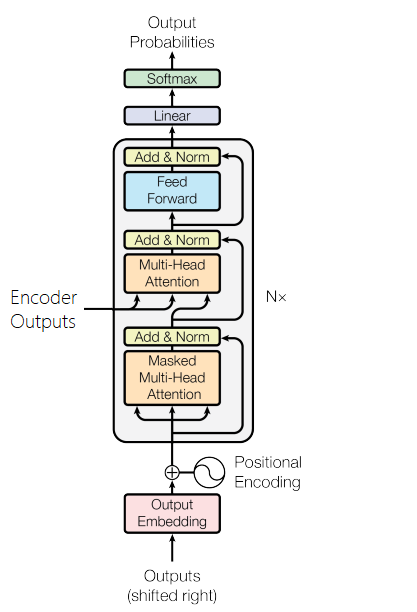

#### 5.6 Decoder

In [141]:
class Decoder(nn.Module):
    def __init__(self, output_dim, hidden_dim, n_layers, n_heads, pff_dim, dropout, device, max_length=100):
        super().__init__()
        self.token_embedding = nn.Embedding(output_dim, embedding_dim=hidden_dim)
        self.positional_encoding = nn.Embedding(max_length, embedding_dim=hidden_dim) # Needed To model position relations which is required for se2seq models # original ppr used sinusoidal encodings.
        self.layers = nn.ModuleList([DecoderLayer(hidden_dim, n_heads, pff_dim, dropout, device) for _ in range(n_layers)])  # we can have Nx of encoder layers
        self.scale = torch.sqrt(torch.FloatTensor([hidden_dim])).to(device)   # Note: Differnt scale from MHA. This is to scale down the token embeddings
        self.dropout = nn.Dropout(dropout)
        self.device = device
        self.fc_out = nn.Linear(in_features=hidden_dim, out_features=output_dim)

    def forward(self, src, target, src_mask, target_mask):
        # target: (bs, target_seq_len), target_mask: (bs, 1, target_seq_len, target_seq_len)
        # src: (bs, src_seq_len), src_mask: (bs, 1, 1, target_seq_len)  # encoder context
        bs = target.shape[0]
        target_seq_len = target.shape[1]

        pos = torch.arange(0, target_seq_len).unsqueeze(dim=0).repeat(bs, 1).to(self.device)  # (target_seq_len,) -> (1, target_seq_len) -> (bs, target_seq_len)
        target = self.dropout((self.token_embedding(target) * self.scale) + self.positional_encoding(pos))    # (bs, target_seq_len) -> (bs, target_seq_len, hidden_dim) + (bs, target_seq_len) -> (bs, target_seq_len, hidden_dim) => (bs, target_seq_len, hidden_dim)
        for layer in self.layers:
            target, attention = layer(src, target, src_mask, target_mask)   # (bs, target_seq_len, hidden_dim), (bs, n_heads, q_target_seq_len, k_src_seq_len)

        output = self.fc_out(target)  # (bs, target_seq_len, output_dim)
        return output, attention # last layer attention and decoder output


#### 5.7 Seq2SeqModel

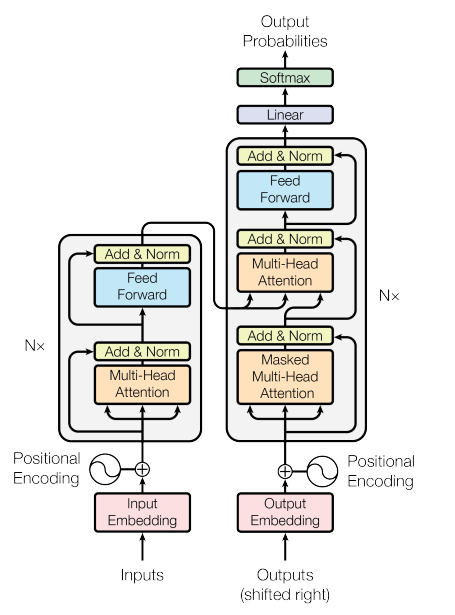

**Putting them together (become Seq2Seq! - a transformer model)**
Our target_mask will look something like this (for a target with 5 tokens):

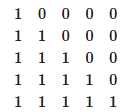

The "subsequent" mask is then logically added with the padding mask, this combines the two masks ensuring both the subsequent tokens and the padding tokens cannot be attended to. For example if the last two tokens were <pad> tokens the mask would look like:

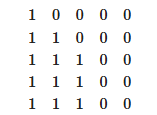

In [142]:
class Seq2SeqTransformerModel(nn.Module):
    def __init__(self, encoder, decoder, src_pad_idx, target_pad_idx, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_pad_idx = src_pad_idx
        self.target_pad_idx = target_pad_idx
        self.device = device

    def create_src_mask(self, src):
        # src: (bs, src_seq_len)
        mask = (src != self.src_pad_idx).unsqueeze(1).unsqueeze(2)  # 1 for non-padding, 0 for padding # (bs, 1, 1, src_seq_len)
        return mask

    def create_target_mask(self, target):
        """
        This is called a causal mask (to prevent attending to future tokens)
        """
        # target: (bs, target_seq_len)
        bs = target.shape[0]
        target_seq_len = target.shape[1]
        padding_mask = (target != self.target_pad_idx).unsqueeze(1).unsqueeze(2)   # (bs, 1, 1, target_seq_len)
        future_mask = torch.tril(torch.ones((target_seq_len, target_seq_len), device=self.device)).bool()  # (target_seq_len, target_seq_len)
        future_mask = future_mask.unsqueeze(0).unsqueeze(1)  # (1, 1, target_seq_len, target_seq_len)
        mask = padding_mask & future_mask  # (bs, 1, target_seq_len, target_seq_len)
        return mask

    def forward(self, src, target):
        # src: (bs, src_seq_len), target: (bs, target_seq_len)
        src_mask = self.create_src_mask(src)    # (bs, 1, 1, src_seq_len)
        target_mask = self.create_target_mask(target)   # (bs, 1, target_seq_len, target_seq_len)

        enc_src = self.encoder(src, src_mask) # (bs, src_seq_len, hidden_dim)
        output, attention = self.decoder(enc_src, target, src_mask, target_mask)  # (bs, target_seq_len, output_dim), (bs, n_heads, target_seq_lrn, src_seq_len)

        return output, attention


In [143]:
import torch
a = torch.tril(torch.ones((5, 5))).bool()
a, a.shape

(tensor([[ True, False, False, False, False],
         [ True,  True, False, False, False],
         [ True,  True,  True, False, False],
         [ True,  True,  True,  True, False],
         [ True,  True,  True,  True,  True]]),
 torch.Size([5, 5]))

### 6. Training

In [144]:
def init_weights(m):
    if hasattr(m, "weight") and m.weight.dim() > 1:
        nn.init.xavier_uniform_(m.weight.data)

In [145]:
def count_parameters(model):
    params = [p.numel() for p in model.parameters() if p.requires_grad]
    for item in params:
        print(f'{item:>6}')
    print(f'______\n{sum(params):>6}')

In [146]:
def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

In [147]:
input_dim = len(vocab_transform[SRC_LANGUAGE])
output_dim = len(vocab_transform[TARGET_LANGUAGE])
hidden_dim = 256
encoder_layers = 3
decoder_layers = 3
encoder_heads = 8
decoder_heads = 8
encoder_pff_dim = 512
decoder_pff_dim = 512
encoder_dropout = 0.1
decoder_dropout = 0.1

SRC_PAD_IDX = PAD_IDX
TARGET_PAD_IDX = PAD_IDX

encoder = Encoder(input_dim, hidden_dim, encoder_layers, encoder_heads, encoder_pff_dim, encoder_dropout, device, max_length=100)
decoder = Decoder(output_dim, hidden_dim, decoder_layers, decoder_heads, decoder_pff_dim, decoder_dropout, device, max_length=100)
model = Seq2SeqTransformerModel(encoder, decoder, SRC_PAD_IDX, TARGET_PAD_IDX, device).to(device)
model.apply(init_weights)

Seq2SeqTransformerModel(
  (encoder): Encoder(
    (token_embedding): Embedding(5207, 256)
    (positional_encoding): Embedding(100, 256)
    (layers): ModuleList(
      (0-2): 3 x EncoderLayer(
        (self_attn_layer_norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (pffd_layer_norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (self_attention): MultiHeadAttention(
          (fc_q): Linear(in_features=256, out_features=256, bias=True)
          (fc_k): Linear(in_features=256, out_features=256, bias=True)
          (fc_v): Linear(in_features=256, out_features=256, bias=True)
          (fc_out): Linear(in_features=256, out_features=256, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (feedforward): PositionWiseFeedForward(
          (fc1): Linear(in_features=256, out_features=512, bias=True)
          (fc2): Linear(in_features=512, out_features=256, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
      

In [148]:
count_parameters(model)

1332992
 25600
   256
   256
   256
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
131072
   512
131072
   256
   256
   256
   256
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
131072
   512
131072
   256
   256
   256
   256
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
131072
   512
131072
   256
1654784
 25600
   256
   256
   256
   256
   256
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
131072
   512
131072
   256
   256
   256
   256
   256
   256
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
131072
   512
131072
   256
   256
   256
   256
   256
   256
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
 65536
   256
131072
   512
131072
   256
1654784
  6464
______
8653888


In [149]:
lr = 0.0005

optimizer = optim.Adam(model.parameters(), lr=lr)
criterion = nn.CrossEntropyLoss(ignore_index=TARGET_PAD_IDX) # combine softmax with cross entropy

Then, we'll define our training loop. As we want our model to predict the `<eos>` token but not have it be an input into our model we simply slice the `<eos>` token off the end of the sequence. Thus:
```
 target = [sos, x1, x2, x3, eos]
 target[:-1] = [sos, x1, x2, x3]
```
 denotes actual target sequence element. We then feed this into the model to get a predicted sequence that should hopefully predict the `<eos>` token:

 ```
 output = [y1, y2, y2, eos]
 ```

 denotes predicted target sequence element. We then calculate our loss using the original target tensor with the `<sos>` token sliced off the front, leaving the `<eos>` token:

 ```
 output = [y1, y2, y2, eos]
 target[1:] = [x1, x2, x3, eos]
 ```

We then calculate our losses and update our parameters as is standard.

In [150]:
def train(model, train_dataloader, optimizer, criterion, clip, loader_length):
    model.train()
    epoch_loss = 0
    for src, src_len, target in train_dataloader:
        src = src.to(device)    # (bs, src_seq_len)
        target = target.to(device)  # (bs, target_seq_len)
        optimizer.zero_grad()

        # Make sure your training loop shifts Targets for Teacher Forcing i,e ensures decoder input doesn’t see <eos>, and model is evaluated against gold next token.
        # Decoder input: SOS, y₁, y₂, ..., yₙ₋₁
        # Ground truth: [sos, y₁, y₂, ..., yₙ, eos] > Shifted Ground truth: [y₁, y₂, ..., yₙ, eos]
        # Decoder output:  y'₁, y'₂, ..., y'ₙ, eos
        # inputs shift right - target[:, :-1] remove the eos, e.g., "<sos> I love sushi" since teaching forcing, the input does not need to have eos
        output, _ = model(src, target[:, :-1])  # (bs, target_seq_len-1, output_dim)

        output_dim = output.shape[-1]
        output = output.reshape(-1, output_dim) # (bs * target_seq_len - 1, output_dim)
        target = target[:, 1:].reshape(-1)     # (bs * target_seq_len - 1)
        # target[:, 1:] remove the sos, e.g., "i love sushi <eos>" since in teaching forcing, the output does not have sos

        loss = criterion(output, target)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        epoch_loss += loss.item()
    return epoch_loss / loader_length

In [151]:
def evaluate(model, val_dataloader, criterion, loader_length):
    model.eval()
    epoch_loss = 0
    with torch.no_grad():
        for src, src_len, target in val_dataloader:
            src = src.to(device) # (bs, src_seq_len)
            target = target.to(device) # (bs, target_seq_len)
            output, _ = model(src, target[:, :-1])  # (bs, target_seq_len-1, output_dim)
            output_dim = output.shape[-1]
            output = output.contiguous().view(-1, output_dim) # (bs * target_seq_len - 1, output_dim)
            target = target[:, 1:].contiguous().view(-1)  # (bs * target_seq_len - 1)
            loss = criterion(output, target)
            epoch_loss += loss.item()
    return epoch_loss / loader_length

Finally, we train our actual model. This model is almost 3x faster than the convolutional sequence-to-sequence model and also achieves a lower validation perplexity!

**Note:**
similar to CNN, this model always has a teacher forcing ratio of 1, i.e. it will always use the ground truth next token from the target sequence (this is simply because CNN do everything in parallel so we cannot have the next token) during training. This means we cannot compare perplexity values against the previous models when they are using a teacher forcing ratio that is not 1. To understand this, try run previous notebooks with teaching forcing ratio of 1, you will get very low perplexity. **

In [152]:
train_loader_length = len(list(iter(train_dataloader)))
val_loader_length   = len(list(iter(val_dataloader)))
test_loader_length  = len(list(iter(test_dataloader)))

In [153]:
import math

best_val_loss = float('inf')
num_epochs = 10
clip = 1

save_path = f"/content/{model.__class__.__name__}.pt"

train_losses = []
val_losses = []

for epoch in range(num_epochs):
    start_time = time.time()
    train_loss = train(model, train_dataloader, optimizer, criterion, clip, train_loader_length)
    val_loss = evaluate(model, val_dataloader, criterion, val_loader_length)
    # For plotting
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    end_time = time.time()
    epoch_mins, epoch_secs = epoch_time(start_time, end_time)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), save_path)
    print(f"Epoch: {epoch+1:02} | Time: {epoch_mins}m {epoch_secs}s")
    print(f"\tTrain Loss: {train_loss:.3f} | Train PPL: {math.exp(train_loss):7.3f}")
    print(f"\t Val. Loss: {val_loss:.3f} |  Val. PPL: {math.exp(val_loss):7.3f}")

    #lower perplexity is better

Epoch: 01 | Time: 0m 14s
	Train Loss: 4.199 | Train PPL:  66.645
	 Val. Loss: 3.213 |  Val. PPL:  24.863
Epoch: 02 | Time: 0m 14s
	Train Loss: 2.899 | Train PPL:  18.152
	 Val. Loss: 2.571 |  Val. PPL:  13.075
Epoch: 03 | Time: 0m 14s
	Train Loss: 2.311 | Train PPL:  10.087
	 Val. Loss: 2.252 |  Val. PPL:   9.510
Epoch: 04 | Time: 0m 14s
	Train Loss: 1.922 | Train PPL:   6.837
	 Val. Loss: 2.049 |  Val. PPL:   7.757
Epoch: 05 | Time: 0m 14s
	Train Loss: 1.638 | Train PPL:   5.144
	 Val. Loss: 1.949 |  Val. PPL:   7.020
Epoch: 06 | Time: 0m 14s
	Train Loss: 1.419 | Train PPL:   4.132
	 Val. Loss: 1.901 |  Val. PPL:   6.689
Epoch: 07 | Time: 0m 14s
	Train Loss: 1.239 | Train PPL:   3.451
	 Val. Loss: 1.858 |  Val. PPL:   6.411
Epoch: 08 | Time: 0m 14s
	Train Loss: 1.087 | Train PPL:   2.965
	 Val. Loss: 1.870 |  Val. PPL:   6.486
Epoch: 09 | Time: 0m 14s
	Train Loss: 0.968 | Train PPL:   2.633
	 Val. Loss: 1.901 |  Val. PPL:   6.691
Epoch: 10 | Time: 0m 14s
	Train Loss: 0.869 | Train PPL

Text(0, 0.5, 'Loss')

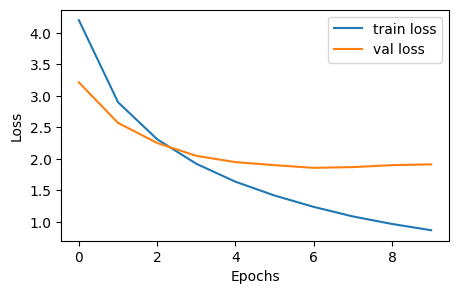

In [159]:
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(5, 3))
ax = fig.add_subplot(1, 1, 1)
ax.plot(train_losses, label="train loss")
ax.plot(val_losses, label="val loss")
plt.legend()
ax.set_xlabel("Epochs")
ax.set_ylabel("Loss")

In [160]:
model.load_state_dict(torch.load(save_path))
test_loss = evaluate(model, test_dataloader, criterion, test_loader_length)

print(f"| Test Loss: {test_loss:.3f} | Test PPL: {math.exp(test_loss):7.3f} |")

| Test Loss: 1.847 | Test PPL:   6.338 |


### 7. Inference

In [156]:
sample[0]

'Two young, White males are outside near many bushes.'

In [157]:
sample[1]

'Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.'

In [161]:
src_text = transforms_pipe[SRC_LANGUAGE](sample[0]).to(device)
src_text

tensor([   2,   19,   25,   15, 1129,  861,   17,   55,   80,  343, 1359,    5,
           3], device='cuda:0')

In [170]:
src_text = src_text.reshape(1, -1) # add batch dimension
src_text.shape

torch.Size([1, 13])

In [162]:
target_text = transforms_pipe[TARGET_LANGUAGE](sample[1]).to(device)
target_text

tensor([   2,   21,   85,  257,   31,   89,   23,   99,    7,   16,  105,    0,
        3497,    4,    3], device='cuda:0')

In [169]:
target_text = target_text.reshape(1, -1) # add batch dimension
target_text.shape

torch.Size([1, 15])

In [166]:
model.load_state_dict(torch.load(save_path))

model.eval()
with torch.no_grad():
    output, attentions = model(src_text, target_text)


In [167]:
output.shape  # bs, targetseqlen, output_dim

torch.Size([1, 15, 6464])

In [168]:
attentions.shape # bs, n_heads, targetseqlen, srcseqlen

torch.Size([1, 8, 15, 13])

In [171]:
output = output.squeeze(dim=0)
output.shape

torch.Size([15, 6464])

In [172]:
# We shall remove the first token since it's zeroes anyway
output = output[1:]
output.shape  # targetseqlen, target_output_dim

torch.Size([14, 6464])

In [173]:
# Then we just take the top token with highest probabilities
output_max = output.argmax(dim=1)
output_max.shape

torch.Size([14])

In [178]:
for pred_token in output_max:
    print(target_mapping[pred_token.item()])

hellhäutige
hellhäutige
Männer
sind
draußen
Freien
neben
der
Nähe
von
von
.
<eos>
.


### 8. Display Attention Map

Let's display the attentions to understand how the source text links with the generated text.

In [179]:
attentions.shape

torch.Size([1, 8, 15, 13])

Since there are 8 heads, we can look at just 1 head for sake of simplicity.

In [180]:
attention = attentions[0, 0, :, :]
attention.shape

torch.Size([15, 13])

In [182]:
src_tokens = ["<sos>"] + tokenization_transform[SRC_LANGUAGE](sample[0]) + ["<eos>"]
src_tokens

['<sos>',
 'Two',
 'young',
 ',',
 'White',
 'males',
 'are',
 'outside',
 'near',
 'many',
 'bushes',
 '.',
 '<eos>']

In [184]:
target_tokens = ["<sos>"] + [target_mapping[token.item()] for token in output_max]
target_tokens

['<sos>',
 'hellhäutige',
 'hellhäutige',
 'Männer',
 'sind',
 'draußen',
 'Freien',
 'neben',
 'der',
 'Nähe',
 'von',
 'von',
 '.',
 '<eos>',
 '.']

In [185]:
def display_attention(sentence, translation, attention):
    fig = plt.figure(figsize=(10,10))
    ax = fig.add_subplot(111)
    attention = attention.squeeze(1).cpu().detach().numpy()
    cax = ax.matshow(attention, cmap="bone")
    ax.tick_params(labelsize=10)
    y_ticks =  [""] + translation
    x_ticks =  [""] + sentence
    ax.set_xticklabels(x_ticks, rotation=45)
    ax.set_yticklabels(y_ticks)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
    plt.show()
    plt.close()

<ipython-input-185-af982aa6b94d>:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_ticks, rotation=45)
<ipython-input-185-af982aa6b94d>:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(y_ticks)


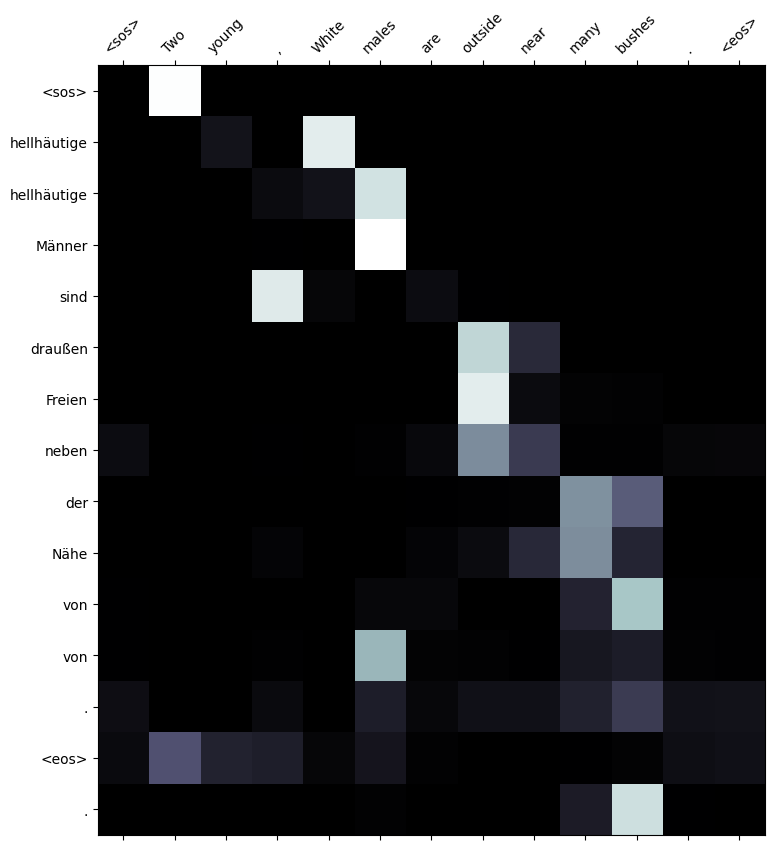

In [186]:
display_attention(src_tokens, target_tokens, attention)

### Tip:

In PyTorch, bmm, mm, and matmul are all functions used for matrix multiplication, but they differ in their behavior and purpose. bmm performs batched matrix multiplication on 3D tensors, mm performs matrix multiplication on 2D tensors, and matmul is a more versatile function that can handle various tensor shapes and perform dot products, matrix products, or batched matrix products depending on the input.

**torch.bmm (Batch Matrix Multiplication):**

- Performs batched matrix multiplication on 3D tensors.
- Expects two 3D tensors, each containing a batch of matrices.
- Does not support broadcasting, meaning the batch sizes must be the same.
- Can be replaced by torch.matmul in most cases.

**torch.mm (Matrix Multiplication):**

- Performs a standard matrix multiplication on 2D tensors.
- Expects two 2D tensors, where the number of columns in the first tensor must equal the number of rows in the second tensor.
- Does not support broadcasting.

**torch.matmul (Matrix Product):**
- A more versatile function that can handle various tensor shapes and perform dot products, matrix products, or batched matrix products depending on the input.
- Can perform element-wise multiplication, dot products, matrix products, or batched matrix products.
- Supports broadcasting.
- In most cases, torch.matmul is a more flexible and preferred option compared to torch.bmm or torch.mm